# Sleep Staging — Exploración Inicial del Dataset

**Objetivo:** Entender la estructura del dataset antes de cualquier preprocesamiento o modelado.  
**Librería principal:** MNE-Python (estándar en neurociencias para señales EEG/PSG).  
**Formato de datos:** EDF (European Data Format), estándar médico para señales fisiológicas.

---
> **Preguntas a responder:**  
> - ¿Cuántos sujetos y cuántos archivos hay?  
> - ¿Todos los archivos tienen los mismos canales y sampling rate?  
> - ¿Las clases están balanceadas?  
> - ¿Hay archivos corruptos o problemáticos?

## 0. Configuración e importaciones

In [17]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import mne

# Reducir mensajes informativos y warnings
mne.set_log_level('WARNING')
warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA_PATH    = "../data/recordings"   # Archivos .edf
LABELS_PATH  = "../data/recordings"   # Archivos _sleepscoring.txt (mismo directorio aquí)

# Colores consistentes para visualizar las etapas del sueño
STAGE_COLORS = {
    'Sleep stage W':  '#e74c3c',
    'Sleep stage N1': '#f39c12',
    'Sleep stage N2': '#3498db',
    'Sleep stage N3': '#2c3e50',
    'Sleep stage R':  '#27ae60',
}

print("MNE version:", mne.__version__)

MNE version: 1.12.1


---
## 1. Inventario de archivos

Analizar qué tenemos.  
Vamos a separar archivos EDF de señales vs. archivos de anotaciones (`_sleepscoring.txt`).

In [2]:
all_files = sorted(os.listdir(DATA_PATH))

# Separar señales de anotaciones
edf_signals = [f for f in all_files if f.endswith('.edf') and 'sleepscoring' not in f]   # contiene las señales
edf_annots  = [f for f in all_files if f.endswith('.edf') and 'sleepscoring' in f]       # contiene las anotaciones (stages)
txt_labels  = [f for f in all_files if f.endswith('.txt')]                               # contiene los labels/etiquetas (stages en formato texto)

print(f"Archivos EDF (señales):      {len(edf_signals)}")
print(f"Archivos EDF (anotaciones):  {len(edf_annots)}")
print(f"Archivos TXT (labels):       {len(txt_labels)}")
print()

# Extraer IDs de sujetos
subject_ids = [f.replace('.edf', '') for f in edf_signals]
print("Primeros 10 sujetos:", subject_ids[:10])
print()

# Verificar que todo sujeto tiene su archivo de labels
missing_labels = [sid for sid in subject_ids
                  if f"{sid}_sleepscoring.txt" not in txt_labels]
if missing_labels:
    print(f"⚠️  Sujetos SIN archivo de labels ({len(missing_labels)}): {missing_labels[:5]}")
else:
    print("✅ Todos los sujetos tienen archivo de labels.")

Archivos EDF (señales):      151
Archivos EDF (anotaciones):  151
Archivos TXT (labels):       151

Primeros 10 sujetos: ['SN001', 'SN002', 'SN003', 'SN004', 'SN005', 'SN006', 'SN007', 'SN008', 'SN009', 'SN010']

✅ Todos los sujetos tienen archivo de labels.


---
## 2. Leer un archivo EDF — inspección

In [13]:
# Leer el primer archivo como
sample_file = edf_signals[0]
sample_path = os.path.join(DATA_PATH, sample_file)

raw = mne.io.read_raw_edf(sample_path, preload=False)

print(raw)
print(type(raw))
dir(raw)


<RawEDF | SN001.edf, 8 x 6566400 (25650.0 s), ~11 KiB, data not loaded>
<class 'mne.io.edf.edf.RawEDF'>


C:\Users\tolot\AppData\Local\Temp\ipykernel_41320\4101329634.py:5: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(sample_path, preload=False)
C:\Users\tolot\AppData\Local\Temp\ipykernel_41320\4101329634.py:5: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(sample_path, preload=False)


['__class__',
 '__contains__',
 '__del__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__enter__',
 '__eq__',
 '__exit__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setitem__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_annotations',
 '_cals',
 '_check_bad_segment',
 '_comp',
 '_cropped_samp',
 '_dtype',
 '_dtype_',
 '_extra_attributes',
 '_filenames',
 '_first_samps',
 '_first_time',
 '_get_buffer_size',
 '_get_channel_positions',
 '_get_duration_string',
 '_getitem',
 '_handle_tmin_tmax',
 '_init_kwargs',
 '_last_samps',
 '_last_time',
 '_orig_units',
 '_parse_get_set_params',
 '_pick_drop_channels',
 '_pick_projs',
 '_preload_data',
 '_projector',
 '_raw_extras',
 '_raw_lengths',
 '_read_comp_grade',
 '_read_picks',
 

In [14]:
print(raw.info)

<Info | 8 non-empty values
 bads: []
 ch_names: EEG F4-M1, EEG C4-M1, EEG O2-M1, EEG C3-M2, EMG chin, EOG E1-M2, ...
 chs: 8 EEG
 custom_ref_applied: False
 highpass: 1.0 Hz
 lowpass: 35.0 Hz
 meas_date: 2001-01-01 23:59:30 UTC
 nchan: 8
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: SN001, sex: 0, last_name: X>
>


In [5]:
print(f"Canales: {len(raw.ch_names)}")
print(f"Canales: {raw.ch_names}")

Canales: 8
Canales: ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2', 'EMG chin', 'EOG E1-M2', 'EOG E2-M2', 'ECG']


In [6]:
print(raw.info.keys())

dict_keys(['acq_pars', 'acq_stim', 'ctf_head_t', 'description', 'dev_head_t', 'dev_ctf_t', 'dig', 'experimenter', 'utc_offset', 'device_info', 'file_id', 'highpass', 'hpi_subsystem', 'kit_system_id', 'helium_info', 'line_freq', 'lowpass', 'meas_date', 'meas_id', 'proj_id', 'proj_name', 'subject_info', 'xplotter_layout', 'gantry_angle', 'bads', 'chs', 'comps', 'events', 'hpi_meas', 'hpi_results', 'projs', 'proc_history', 'custom_ref_applied', 'sfreq', 'ch_names', 'nchan'])


In [7]:
print(f"Archivo:            {sample_file}")
print(f"Canales ({len(raw.ch_names)}):     {raw.ch_names}")
print(f"Frecuencia muestreo: {raw.info['sfreq']} Hz")
print(f"Duración:           {raw.times[-1]/3600:.2f} horas ({raw.times[-1]:.0f} seg)")
print(f"Total de muestras:  {raw.n_times:,}")
print()

# Tipos de canal detectados automáticamente por MNE
ch_types = {}

print("Tipos de canal detectados:")
for ch in raw.ch_names:
    detected_type = raw.get_channel_types([ch])[0]
    ch_types[ch] = detected_type
    print(f"  {ch}: {ch_types[ch]}")


Archivo:            SN001.edf
Canales (8):     ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2', 'EMG chin', 'EOG E1-M2', 'EOG E2-M2', 'ECG']
Frecuencia muestreo: 256.0 Hz
Duración:           7.12 horas (25650 seg)
Total de muestras:  6,566,400

Tipos de canal detectados:
  EEG F4-M1: eeg
  EEG C4-M1: eeg
  EEG O2-M1: eeg
  EEG C3-M2: eeg
  EMG chin: eeg
  EOG E1-M2: eeg
  EOG E2-M2: eeg
  ECG: eeg


---
## 3. Visualización de señales crudas

Se procede a graficar los **primeros 5 minutos** de grabación. Además, se normaliza por canal para poder compararlos en la misma figura (cada señal tiene escala distinta).



C:\Users\tolot\AppData\Local\Temp\ipykernel_41320\775368851.py:2: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_crop = mne.io.read_raw_edf(
C:\Users\tolot\AppData\Local\Temp\ipykernel_41320\775368851.py:2: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_crop = mne.io.read_raw_edf(


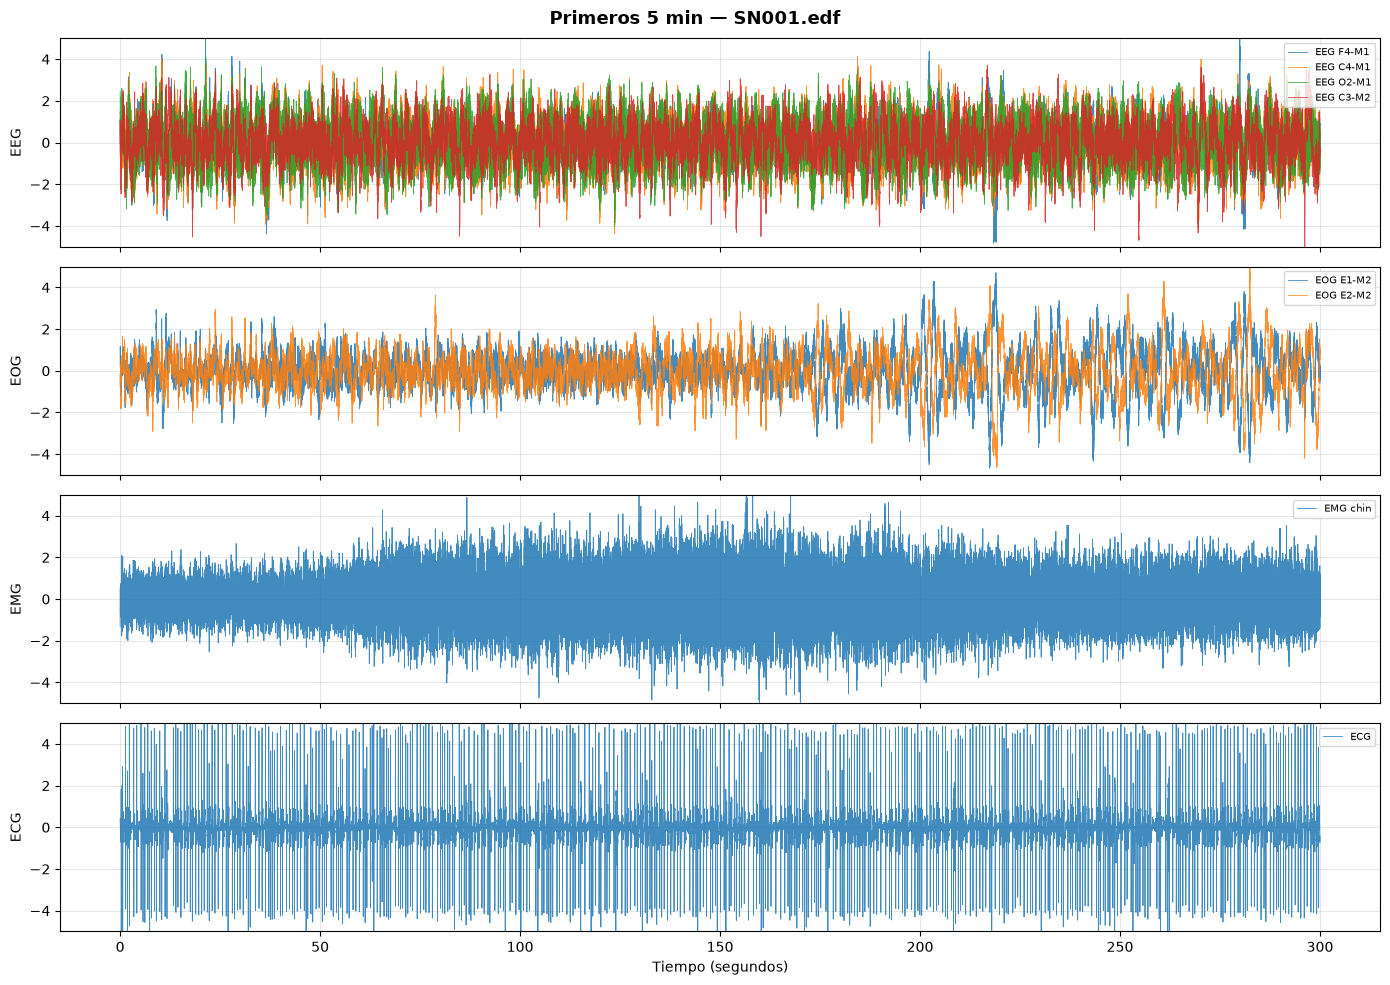

In [8]:
# Recortar los primeros 5 minutos sin cargar toda la grabación en memoria
raw_crop = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
).crop(tmin=0, tmax=300)

times = raw_crop.times

# Agrupar canales por tipo
channel_groups = {
    group: [ch for ch in raw_crop.ch_names if ch.startswith(group)]
    for group in ["EEG", "EOG", "EMG", "ECG"]
}

# Conservar únicamente grupos presentes en la grabación
channel_groups = {
    group: channels
    for group, channels in channel_groups.items()
    if channels
}

# Crear un subplot por tipo de señal
fig, axes = plt.subplots(
    len(channel_groups),
    1,
    figsize=(14, 10),
    sharex=True
)

fig.suptitle(
    f"Primeros 5 min — {sample_file}",
    fontsize=13,
    fontweight="bold"
)

for ax, (group, channels) in zip(axes, channel_groups.items()):

    # Extraer solamente los canales del grupo
    group_data = raw_crop.get_data(picks=channels)

    # Normalizar cada canal a media 0 y desvío estándar 1
    group_data = (
        group_data - group_data.mean(axis=1, keepdims=True)
    ) / (
        group_data.std(axis=1, keepdims=True) + 1e-10
    )

    # Graficar los canales superpuestos
    for signal, channel in zip(group_data, channels):
        ax.plot(
            times,
            signal,
            lw=0.6,
            alpha=0.85,
            label=channel
        )

    ax.set_ylabel(group)
    ax.set_ylim(-5, 5)
    ax.legend(loc="upper right", fontsize=7)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Tiempo (segundos)")

plt.tight_layout()
plt.show()

del raw_crop

### Observaciones iniciales sobre las señales crudas

En los primeros 5 minutos del sujeto `SN001` no se observan canales completamente planos ni señales ausentes. Los cuatro canales EEG presentan actividad continua, mientras que las señales EOG muestran variaciones compatibles con movimientos oculares. La señal EMG presenta cambios en su amplitud a lo largo del tiempo, posiblemente asociados con variaciones en la actividad muscular. El ECG muestra picos repetitivos y regulares, vinculados con la actividad cardíaca.


C:\Users\tolot\AppData\Local\Temp\ipykernel_41320\2470292253.py:6: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_crop = mne.io.read_raw_edf(
C:\Users\tolot\AppData\Local\Temp\ipykernel_41320\2470292253.py:6: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_crop = mne.io.read_raw_edf(


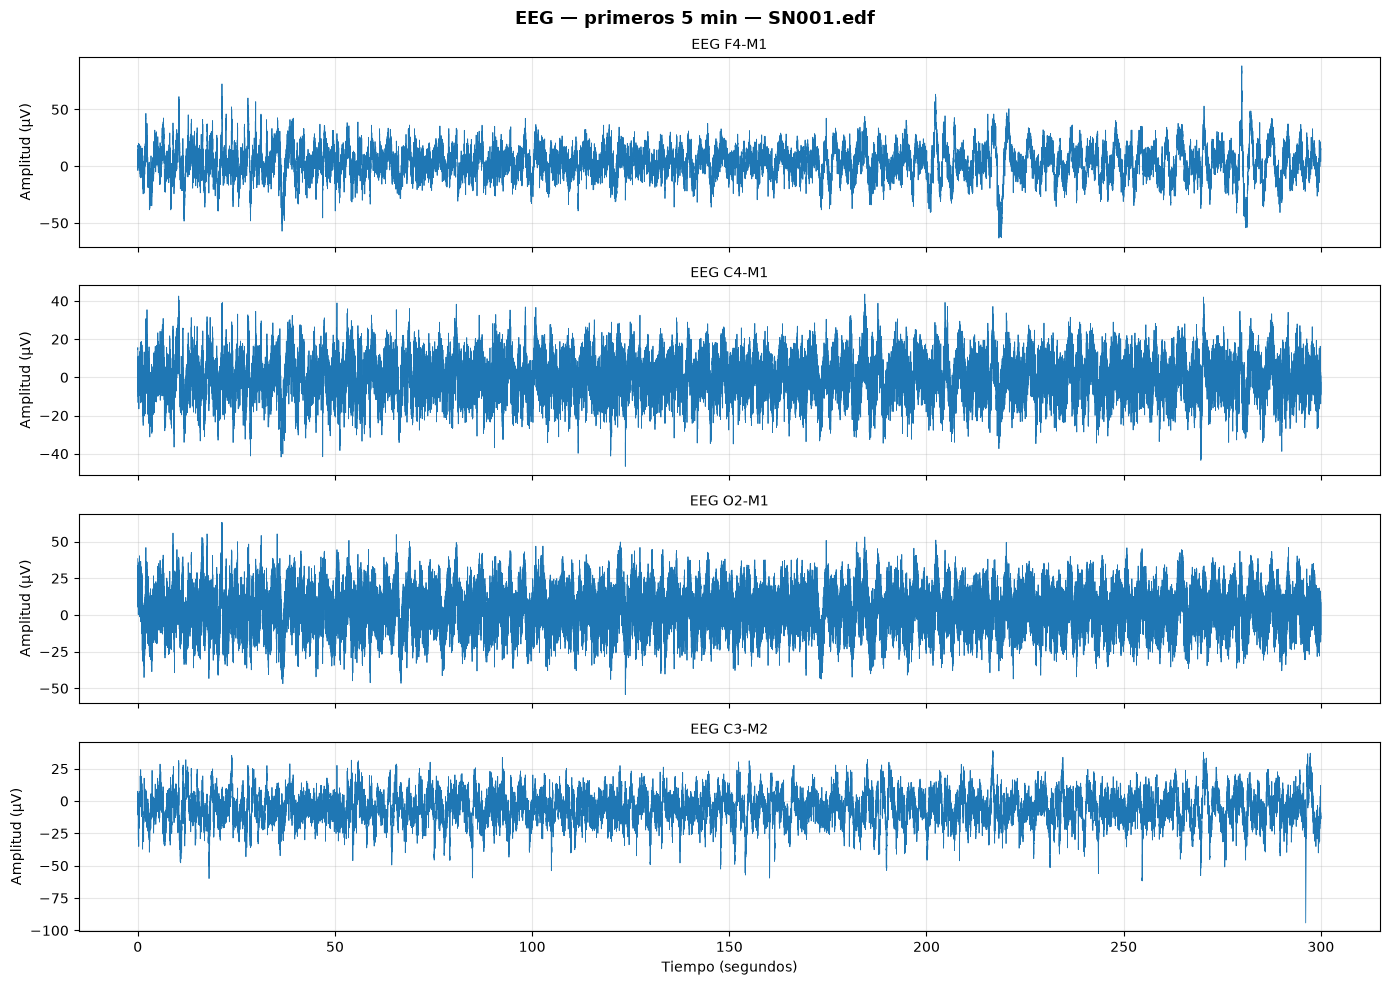

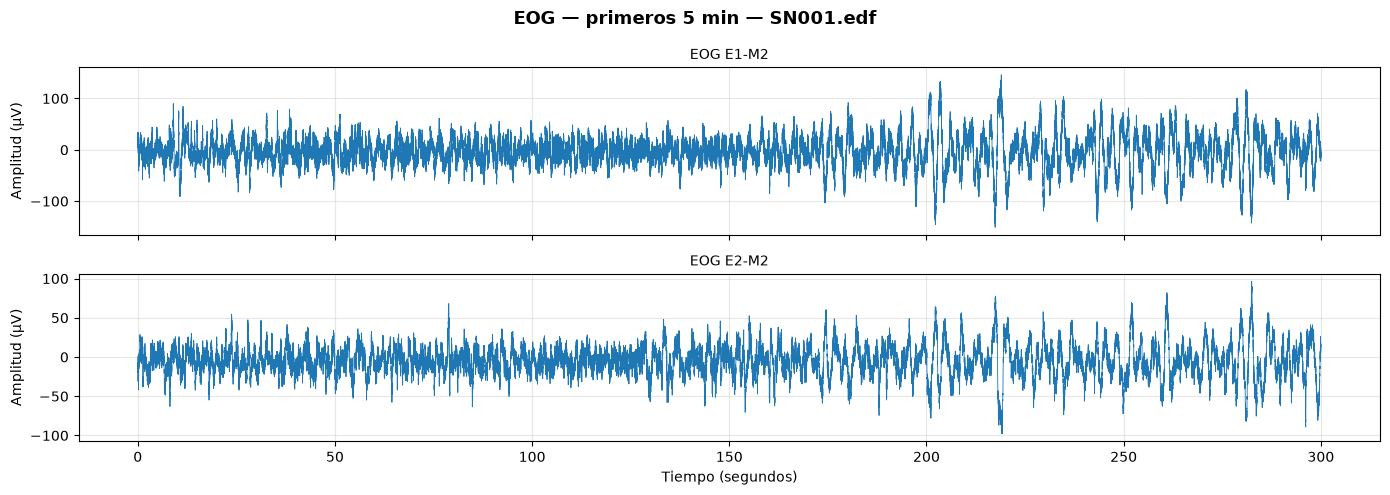

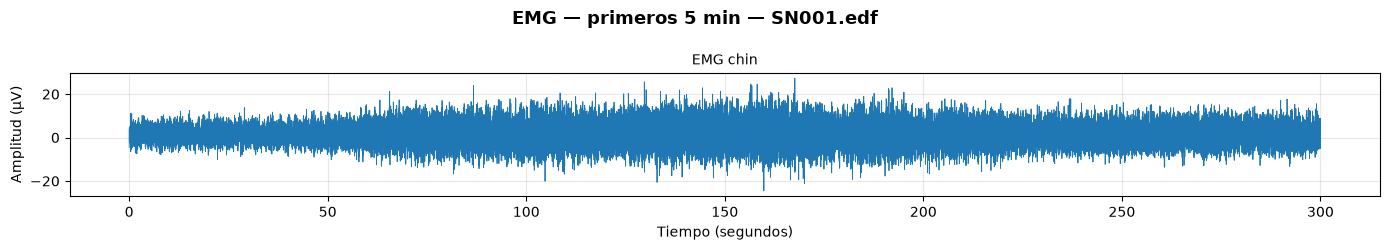

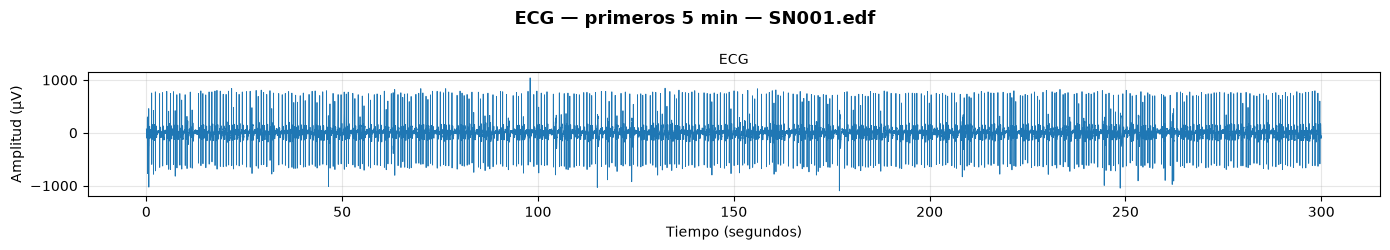

In [9]:
# ============================================================
# Visualización de señales crudas sin normalización
# ============================================================

# Primeros 5 minutos de la grabación
raw_crop = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
).crop(tmin=0, tmax=300)

times = raw_crop.times

# Agrupar canales según su nombre
channel_groups = {
    group: [ch for ch in raw_crop.ch_names if ch.startswith(group)]
    for group in ["EEG", "EOG", "EMG", "ECG"]
}

# Graficar cada tipo de señal por separado
for group, channels in channel_groups.items():

    if not channels:
        continue

    # Obtener únicamente los canales del grupo y convertir V → µV
    group_data = raw_crop.get_data(picks=channels) * 1e6

    fig, axes = plt.subplots(
        len(channels),
        1,
        figsize=(14, 2.5 * len(channels)),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    fig.suptitle(
        f"{group} — primeros 5 min — {sample_file}",
        fontsize=13,
        fontweight="bold"
    )

    for ax, signal_uv, channel in zip(axes, group_data, channels):
        ax.plot(times, signal_uv, linewidth=0.6)
        ax.set_title(channel, fontsize=10)
        ax.set_ylabel("Amplitud (µV)")
        ax.grid(alpha=0.3)

    axes[-1].set_xlabel("Tiempo (segundos)")

    plt.tight_layout()
    plt.show()

del raw_crop

---
## 4. Análisis de canales en todo el dataset

La idea principal en este punto, es verificar que todos los archivos comparten los mismos canales.  

In [18]:
# ============================================================
# Consistencia de canales, sampling rate y duración
# ============================================================

channel_info = []

for file_name in edf_signals:

    file_path = os.path.join(DATA_PATH, file_name)

    try:
        raw = mne.io.read_raw_edf(
            file_path,
            preload=False,
            verbose=False
        )

        channel_info.append({
            "subject": file_name.replace(".edf", ""),
            "n_channels": len(raw.ch_names),
            "channels": tuple(sorted(raw.ch_names)),
            "sfreq": raw.info["sfreq"],
            "duration_h": raw.duration / 3600
        })

        raw.close()

    except Exception as error:
        print(f"❌ Error leyendo {file_name}: {error}")


df_info = pd.DataFrame(channel_info)

# Verificar si todos los sujetos tienen los mismos canales
unique_channel_sets = df_info["channels"].nunique()

print(
    f"Conjuntos de canales distintos en el dataset: "
    f"{unique_channel_sets}"
)

if unique_channel_sets == 1:
    print("✅ Todos los archivos tienen exactamente los mismos canales.")
else:
    print("⚠️ Hay variación en los canales — revisar antes de modelar.")
    print(df_info["channels"].value_counts())


# Verificar sampling rates
print(
    f"\nSampling rates presentes: "
    f"{df_info['sfreq'].unique()}"
)

# Resumen general
print("\nResumen general:")
print(
    df_info[
        ["n_channels", "sfreq", "duration_h"]
    ].describe().round(2)
)

Conjuntos de canales distintos en el dataset: 1
✅ Todos los archivos tienen exactamente los mismos canales.

Sampling rates presentes: [256.]

Resumen general:
       n_channels  sfreq  duration_h
count       151.0  151.0      151.00
mean          8.0  256.0        7.58
std           0.0    0.0        1.24
min           8.0  256.0        3.92
25%           8.0  256.0        6.97
50%           8.0  256.0        7.52
75%           8.0  256.0        8.39
max           8.0  256.0       10.93


---
## 5. Distribución de duraciones

Las grabaciones PSG suelen durar entre 6 y 9 horas. Si hay grabaciones demasiado cortas, esto podría indicar archivos incompletos o corruptos.

Estadísticas de duración (horas):
  Mínima:   3.92 h
  Máxima:   10.93 h
  Promedio: 7.58 h
  Mediana:  7.52 h

Grabaciones cortas (< 4.0h): 1
   subject  duration_h
60   SN062    3.917778


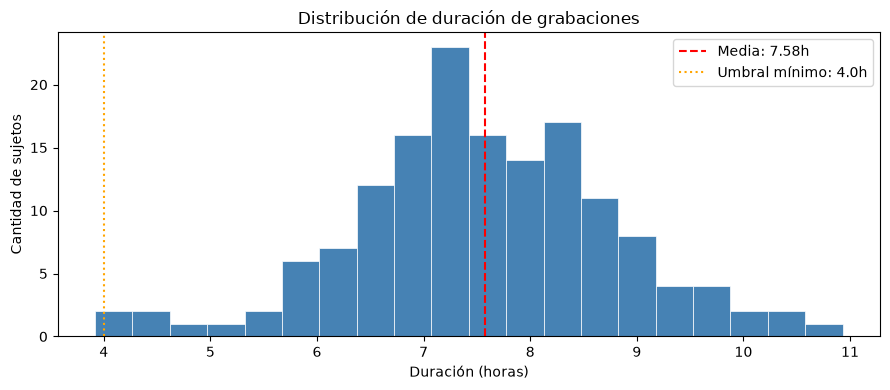

In [19]:
durations = df_info['duration_h']

print("Estadísticas de duración (horas):")
print(f"  Mínima:   {durations.min():.2f} h")
print(f"  Máxima:   {durations.max():.2f} h")
print(f"  Promedio: {durations.mean():.2f} h")
print(f"  Mediana:  {durations.median():.2f} h")

# Detectar outliers: grabaciones anormalmente cortas (< 4 horas)
SHORT_THRESHOLD = 4.0
short_recordings = df_info[durations < SHORT_THRESHOLD]
if len(short_recordings) > 0:
    print(f"\nGrabaciones cortas (< {SHORT_THRESHOLD}h): {len(short_recordings)}")
    print(short_recordings[['subject', 'duration_h']])
else:
    print(f"\n✅ Ninguna grabación menor a {SHORT_THRESHOLD} horas.")

# Histograma
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(durations, bins=20, color='steelblue', edgecolor='white', linewidth=0.5)
ax.axvline(durations.mean(), color='red', ls='--', label=f'Media: {durations.mean():.2f}h')
ax.axvline(SHORT_THRESHOLD, color='orange', ls=':', label=f'Umbral mínimo: {SHORT_THRESHOLD}h')
ax.set_xlabel("Duración (horas)")
ax.set_ylabel("Cantidad de sujetos")
ax.set_title("Distribución de duración de grabaciones")
ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Leer y explorar labels (hypnograms)

El **hypnogram** es una secuencia temporal de etapas de sueño, epoch por epoch, donde cada uno dura 30 segundos (estándar AASM).  
Esta será la variable target en el modelado.

In [20]:
def load_hypnogram(txt_path):
    """
    Lee el archivo de anotaciones y devuelve solo los sleep stages.
    Descarta eventos puntuales (Lights off, arousals, etc.).
    """
    df = pd.read_csv(txt_path)
    df.columns = df.columns.str.strip()  # limpiar espacios innecesarios en nombres de columnas
    df['Annotation'] = df['Annotation'].str.strip() # limpiar espacios en anotaciones
    # Quedarse solo con epochs de 30s (los sleep stages)
    # Se crea una mascara booleana para filtrar solo las filas donde 'Annotation' comienza con 'Sleep stage'
    stages = df[df['Annotation'].str.startswith('Sleep stage')].copy()
    stages = stages.reset_index(drop=True) # reiniciar índices después de filtrar
    return stages

# Leer labels del sujeto de ejemplo
sample_labels_path = os.path.join(LABELS_PATH, sample_file.replace('.edf', '_sleepscoring.txt'))
labels_df = load_hypnogram(sample_labels_path)

print(f"Epochs totales: {len(labels_df)}")
print(f"Duración cubierta: {len(labels_df) * 30 / 3600:.2f} horas")
print()
print("Distribución de stages:")
print(labels_df['Annotation'].value_counts())
print()
print("Primeras filas:")
display(labels_df.head(10))

Epochs totales: 854
Duración cubierta: 7.12 horas

Distribución de stages:
Annotation
Sleep stage N2    430
Sleep stage W     151
Sleep stage R     141
Sleep stage N1    109
Sleep stage N3     23
Name: count, dtype: int64

Primeras filas:


,Date,Time,Recording onset,Duration,Annotation,Linked channel
0,01.01.01,23.59.30,0.0,30,Sleep stage W,
1,02.01.01,00.00.00,30.0,30,Sleep stage W,
2,02.01.01,00.00.30,60.0,30,Sleep stage W,
3,02.01.01,00.01.00,90.0,30,Sleep stage W,
4,02.01.01,00.01.30,120.0,30,Sleep stage W,
5,02.01.01,00.02.00,150.0,30,Sleep stage W,
6,02.01.01,00.02.30,180.0,30,Sleep stage W,
7,02.01.01,00.03.00,210.0,30,Sleep stage W,
8,02.01.01,00.03.30,240.0,30,Sleep stage N1,
9,02.01.01,00.04.00,270.0,30,Sleep stage N1,


In [21]:
print(labels_df['Linked channel'].value_counts())

Linked channel
    854
Name: count, dtype: int64


### 6.1 Hypnogram visual

El hypnogram muestra la arquitectura del sueño. Algo esperable, es notar ciclos de ~90 minutos con descenso progresivo hacia N2/N3 al inicio y más REM hacia el final de la noche.

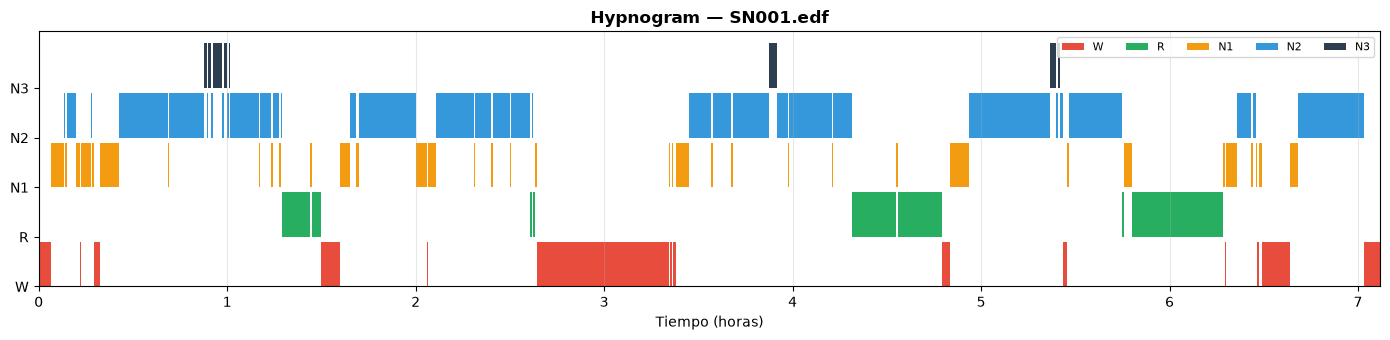

In [25]:
from matplotlib.patches import Patch

# Orden vertical de las etapas
STAGE_ORDER = {
    "Sleep stage W":  0,
    "Sleep stage R":  1,
    "Sleep stage N1": 2,
    "Sleep stage N2": 3,
    "Sleep stage N3": 4,
}

# Convertir las etiquetas a valores numéricos
stage_num = labels_df["Annotation"].map(STAGE_ORDER)

# Cada epoch dura 30 segundos
epoch_h = 30 / 3600
time_h = np.arange(len(labels_df)) * epoch_h

# Color correspondiente a cada epoch
colors = labels_df["Annotation"].map(STAGE_COLORS).fillna("gray")

fig, ax = plt.subplots(figsize=(14, 3.5))

# Dibujar un bloque por epoch
ax.bar(
    time_h,
    height=0.9,
    bottom=stage_num,
    width=epoch_h,
    align="edge",
    color=colors
)

# Etiquetas del eje Y
ax.set_yticks(list(STAGE_ORDER.values()))
ax.set_yticklabels([
    stage.replace("Sleep stage ", "")
    for stage in STAGE_ORDER
])

ax.set_xlabel("Tiempo (horas)")
ax.set_title(f"Hypnogram — {sample_file}", fontweight="bold")
ax.set_xlim(0, len(labels_df) * epoch_h)
ax.grid(axis="x", alpha=0.3)

# Leyenda
stages_present = labels_df["Annotation"].unique()

legend_elements = [
    Patch(
        facecolor=STAGE_COLORS[stage],
        label=stage.replace("Sleep stage ", "")
    )
    for stage in STAGE_ORDER
    if stage in stages_present
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    fontsize=8,
    ncol=5
)

plt.tight_layout()
plt.show()

---
## 7. Distribución de clases — todo el dataset

El **desbalance de clases** es uno de los problemas más importantes en sleep staging.  
En general, N2 suele dominar, mientras que N1 y N3 son minoritarios. Si no se trata con cuidado, el modelo tenderá a predecir siempre N2.

In [26]:
# ============================================================
# Distribución global de sleep stages
# ============================================================

all_stages = []

for file_name in edf_signals:

    labels_path = os.path.join(
        LABELS_PATH,
        file_name.replace(".edf", "_sleepscoring.txt")
    )

    if not os.path.exists(labels_path):
        continue

    try:
        labels = load_hypnogram(labels_path)
        all_stages.extend(labels["Annotation"])

    except Exception as error:
        print(f"❌ Error leyendo {file_name}: {error}")


# Conteos y porcentajes
stage_counts = pd.Series(all_stages).value_counts()

# Mantener un orden consistente de stages
stage_order = [
    "Sleep stage W",
    "Sleep stage R",
    "Sleep stage N1",
    "Sleep stage N2",
    "Sleep stage N3"
]

stage_counts = stage_counts.reindex(stage_order, fill_value=0)
stage_pct = stage_counts / stage_counts.sum() * 100

# Resumen
stage_summary = pd.DataFrame({
    "Epochs": stage_counts,
    "Porcentaje": stage_pct.round(1)
})

print("Distribución global de sleep stages:")
display(stage_summary)

print(f"Total epochs: {stage_counts.sum():,}")
print(f"Horas totales anotadas: {stage_counts.sum() * 30 / 3600:.1f} h")

# Ratio entre clase mayoritaria y minoritaria
ratio = stage_counts.max() / stage_counts.min()
print(f"Ratio de desbalance (max/min): {ratio:.1f}x")

Distribución global de sleep stages:


,Epochs,Porcentaje
Sleep stage W,23686,17.3
Sleep stage R,21255,15.5
Sleep stage N1,15548,11.3
Sleep stage N2,50083,36.5
Sleep stage N3,26671,19.4


Total epochs: 137,243
Horas totales anotadas: 1143.7 h
Ratio de desbalance (max/min): 3.2x


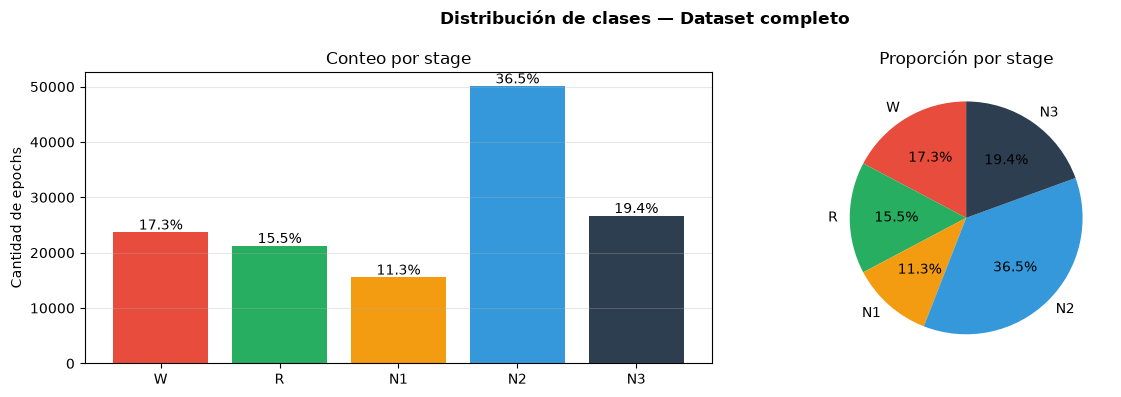

In [27]:
# Visualización
short_labels = [
    stage.replace("Sleep stage ", "")
    for stage in stage_counts.index
]

colors = [
    STAGE_COLORS[stage]
    for stage in stage_counts.index
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(
    "Distribución de clases — Dataset completo",
    fontweight="bold"
)

# Conteos
ax1.bar(
    short_labels,
    stage_counts,
    color=colors
)

for i, (count, pct) in enumerate(zip(stage_counts, stage_pct)):
    ax1.text(
        i,
        count + stage_counts.max() * 0.01,
        f"{pct:.1f}%",
        ha="center"
    )

ax1.set_ylabel("Cantidad de epochs")
ax1.set_title("Conteo por stage")
ax1.grid(axis="y", alpha=0.3)

# Proporciones
ax2.pie(
    stage_counts,
    labels=short_labels,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90
)

ax2.set_title("Proporción por stage")

plt.tight_layout()
plt.show()

---
## 8. Estadísticas de señal por canal

Analizamos amplitud, media y varianza de cada canal.  


In [29]:
# Cargar señal del sujeto de ejemplo (completa)
raw_full = mne.io.read_raw_edf(sample_path, preload=True, verbose=False)
# Obtener todas las señales en formato numpy (shape: n_canales x n_muestras)
data_all, _ = raw_full.get_data(return_times=True)

# Estadísticas por canal
stats_rows = []
for i, ch_name in enumerate(raw_full.ch_names):
    sig = data_all[i]
    stats_rows.append({
        'Canal':      ch_name,
        'Media (µV)': sig.mean() * 1e6,
        'Std (µV)':   sig.std() * 1e6,
        'Min (µV)':   sig.min() * 1e6,
        'Max (µV)':   sig.max() * 1e6,
        'Rango (µV)': (sig.max() - sig.min()) * 1e6,
        '% NaN':      np.isnan(sig).mean() * 100,
        '% plano':    (np.diff(sig) == 0).mean() * 100,  # % de muestras sin cambio
    })

df_stats = pd.DataFrame(stats_rows).set_index('Canal').round(3)
display(df_stats)

# Alertas automáticas
print()
if df_stats['% NaN'].max() > 0:
    print("⚠️  Hay valores NaN en algún canal.")
else:
    print("✅ No hay valores NaN.")

flat_channels = df_stats[df_stats['% plano'] > 20].index.tolist()
if flat_channels:
    print(f"⚠️  Canales con muchos segmentos planos (>20%): {flat_channels}")
else:
    print("✅ Ningún canal tiene segmentos planos excesivos.")

,Media (µV),Std (µV),Min (µV),Max (µV),Rango (µV),% NaN,% plano
Canal,,,,,,,
EEG F4-M1,3.706,39.765,-800.000,800.000,1600.000,0.0,0.354
EEG C4-M1,0.079,39.324,-800.000,800.000,1600.000,0.0,0.175
EEG O2-M1,3.248,29.999,-800.000,800.000,1600.000,0.0,0.215
EEG C3-M2,-5.548,47.948,-800.000,800.000,1600.000,0.0,0.263
EMG chin,1.611,4.777,-402.191,345.501,747.692,0.0,0.369
EOG E1-M2,-3.181,46.648,-800.000,800.000,1600.000,0.0,0.320
EOG E2-M2,-4.836,46.175,-800.000,800.000,1600.000,0.0,0.337
ECG,7.439,122.414,-2400.000,2400.000,4800.000,0.0,0.349



✅ No hay valores NaN.
✅ Ningún canal tiene segmentos planos excesivos.


---
## 9. Power Spectral Density (PSD)

La PSD muestra cómo se distribuye la energía de la señal en el dominio frecuencial.  
Las bandas de interés en sleep staging son:

| Banda | Rango | Relevancia |
|-------|-------|------------|
| Delta | 0.5–4 Hz | N3 (sueño profundo) |
| Theta | 4–8 Hz | N1, REM |
| Alpha | 8–13 Hz | W (relajado con ojos cerrados) |
| Sigma | 12–15 Hz | N2 (sleep spindles) |
| Beta | 15–30 Hz | W (activo) |

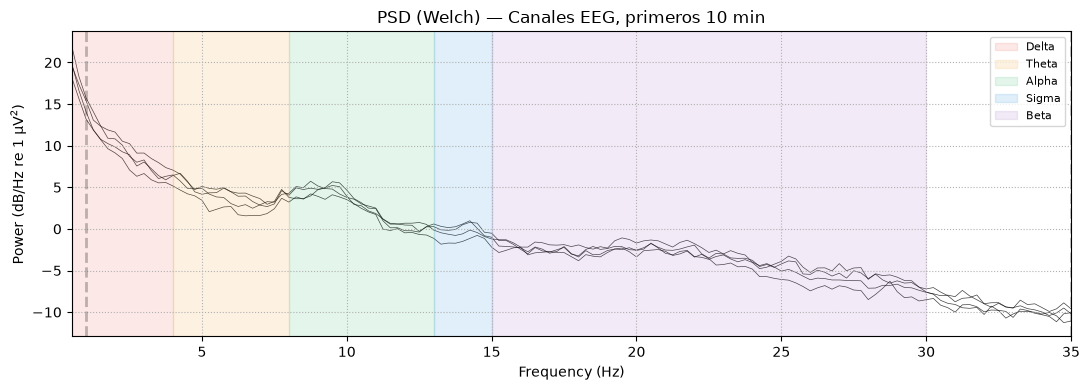

In [28]:
# ============================================================
# Densidad espectral de potencia (PSD) en canales EEG
# ============================================================

# Primeros 10 minutos de la grabación
raw_psd = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
).crop(tmin=0, tmax=600)

# Seleccionar canales EEG
eeg_channels = [
    ch for ch in raw_psd.ch_names
    if ch.startswith("EEG")
]

# PSD mediante el método de Welch
spectrum = raw_psd.compute_psd(
    method="welch",
    fmin=0.5,
    fmax=35,
    n_fft=1024,
    picks=eeg_channels
)

# Visualización
fig, ax = plt.subplots(figsize=(11, 4))

spectrum.plot(
    axes=ax,
    show=False
)

ax.set_title("PSD (Welch) — Canales EEG, primeros 10 min")

# Bandas de frecuencia
freq_bands = [
    (0.5, 4,  "Delta", "#e74c3c", 0.12),
    (4,   8,  "Theta", "#f39c12", 0.12),
    (8,   13, "Alpha", "#27ae60", 0.12),
    (13,  15, "Sigma", "#3498db", 0.15),
    (15,  30, "Beta",  "#9b59b6", 0.12),
]

for fmin, fmax, label, color, alpha in freq_bands:
    ax.axvspan(
        fmin,
        fmax,
        color=color,
        alpha=alpha,
        label=label
    )

ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

raw_psd.close()

---
## 10. PSD comparado por sleep stage

La firma espectral de cada stage es distinta y será la base del feature engineering.  
Esperamos ver delta dominante en N3, spindles (12-15Hz) en N2, theta en REM.

In [29]:
from scipy.signal import welch

# ============================================================
# PSD promedio por sleep stage
# ============================================================

eeg_channel = "EEG C4-M1"

# Cargar señal
raw_stage = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
)

sfreq = raw_stage.info["sfreq"]
epoch_samples = int(30 * sfreq)

# Cargar únicamente el canal EEG seleccionado
signal = raw_stage.get_data(picks=[eeg_channel])[0]

# Cargar labels
labels = load_hypnogram(sample_labels_path)

# Analizar solamente epochs con señal y label disponibles
n_epochs = min(
    len(labels),
    len(signal) // epoch_samples
)

# Una lista de PSDs para cada stage
psd_by_stage = {
    stage: []
    for stage in STAGE_ORDER
}

# Calcular PSD de cada epoch
for i in range(n_epochs):

    stage = labels.iloc[i]["Annotation"]

    if stage not in psd_by_stage:
        continue

    start = i * epoch_samples
    end = start + epoch_samples

    epoch_signal = signal[start:end]

    freqs, psd = welch(
        epoch_signal,
        fs=sfreq,
        nperseg=512
    )

    mask = (freqs >= 0.5) & (freqs <= 35)

    psd_by_stage[stage].append(
        psd[mask]
    )

# Frecuencias que se van a mostrar
freqs_plot = freqs[mask]

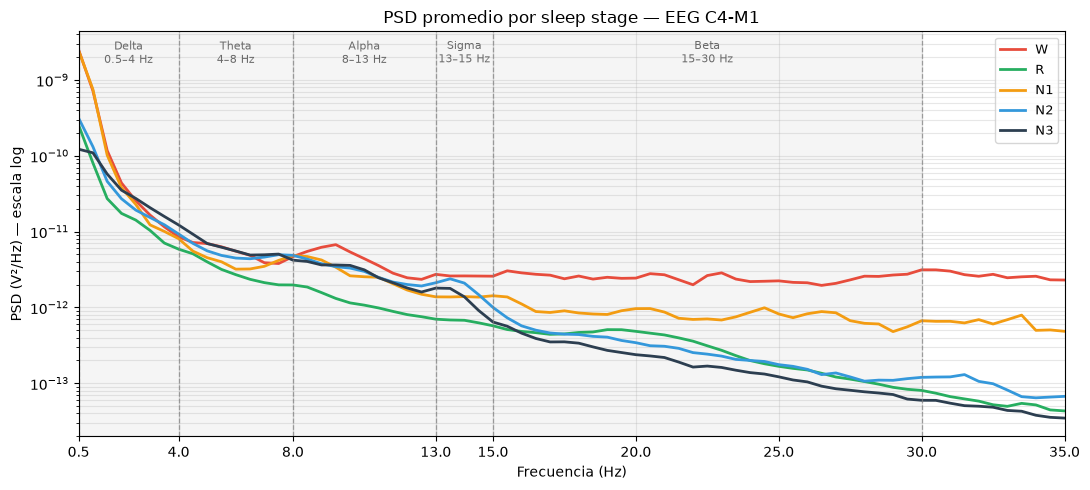

In [30]:
fig, ax = plt.subplots(figsize=(11, 5))

# PSD promedio de cada stage
for stage, psds in psd_by_stage.items():

    if not psds:
        continue

    mean_psd = np.mean(psds, axis=0)

    ax.semilogy(
        freqs_plot,
        mean_psd,
        color=STAGE_COLORS.get(stage, "gray"),
        lw=2,
        label=stage.replace("Sleep stage ", "")
    )


# Bandas de frecuencia
freq_bands = [
    (0.5, 4,  "Delta"),
    (4,   8,  "Theta"),
    (8,   13, "Alpha"),
    (13,  15, "Sigma"),
    (15,  30, "Beta"),
]

for fmin, fmax, name in freq_bands:

    ax.axvspan(
        fmin,
        fmax,
        color="gray",
        alpha=0.08
    )

    ax.axvline(
        fmin,
        color="gray",
        linestyle="--",
        linewidth=0.9,
        alpha=0.7
    )

    ax.text(
        (fmin + fmax) / 2,
        0.98,
        f"{name}\n{fmin:g}–{fmax:g} Hz",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=8,
        color="dimgray"
    )

# Último límite de bandas
ax.axvline(
    30,
    color="gray",
    linestyle="--",
    linewidth=0.9,
    alpha=0.7
)

ax.set(
    xlabel="Frecuencia (Hz)",
    ylabel="PSD (V²/Hz) — escala log",
    title=f"PSD promedio por sleep stage — {eeg_channel}",
    xlim=(0.5, 35)
)

ax.set_xticks([0.5, 4, 8, 13, 15, 20, 25, 30, 35])
ax.legend(fontsize=9)
ax.grid(which="both", alpha=0.3)

plt.tight_layout()
plt.show()

raw_stage.close()

### PSD promedio por etapa de sueño

En esta sección se utilizó el canal EEG central `EEG C4-M1` y se dividió la señal en epochs de 30 segundos. Para cada epoch se calculó la PSD mediante el método de Welch y luego se agruparon los resultados según la etapa de sueño (`W`, `R`, `N1`, `N2` y `N3`).

Finalmente, se graficó la PSD promedio de cada etapa y se marcaron las bandas frecuenciales principales:

* **Delta:** 0.5–4 Hz
* **Theta:** 4–8 Hz
* **Alpha:** 8–13 Hz
* **Sigma:** 13–15 Hz
* **Beta:** 15–30 Hz

Como observación inicial, se aprecia que `N3` presenta mayor potencia relativa en frecuencias bajas, mientras que `W` conserva mayor potencia en frecuencias medias y altas. Las diferencias entre etapas no son perfectamente separables, pero muestran que el contenido frecuencial del EEG varía según el sleep stage.


---
## 11. Calidad de señal — detección de problemas

Antes de modelar, necesitamos identificar epochs problemáticos.  
Criterios comunes:
- **Amplitud extrema:** pico > 500 µV puede considerarse artefacto (movimiento, electrodo suelto)
- **Segmento plano:** señal constante por > 1 segundo = electrodo desconectado
- **Varianza muy baja:** canal prácticamente muerto

In [31]:
def has_flat_segment(signal, min_samples):
    """True si existe un tramo de al menos min_samples valores iguales."""
    repeated = np.diff(signal) == 0
    boundaries = np.r_[True, ~repeated, True]
    run_lengths = np.diff(np.flatnonzero(boundaries))

    return run_lengths.max() >= min_samples

In [33]:
# ============================================================
# Detección de epochs EEG sospechosos
# ============================================================

AMPLITUDE_THRESHOLD_UV = 500   # µV
FLAT_DURATION_S = 1.0          # duración mínima considerada sospechosa


def has_flat_segment(signal, min_samples):
    """True si hay al menos min_samples valores consecutivos iguales."""
    repeated = np.diff(signal) == 0
    boundaries = np.r_[True, ~repeated, True]
    run_lengths = np.diff(np.flatnonzero(boundaries))

    return run_lengths.max() >= min_samples


# Leer la grabación
raw_qc = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
)

sfreq = raw_qc.info["sfreq"]
epoch_samples = int(30 * sfreq)
flat_samples = int(FLAT_DURATION_S * sfreq)

# Seleccionar y cargar solamente canales EEG
eeg_channels = [
    ch for ch in raw_qc.ch_names
    if ch.startswith("EEG")
]

eeg_data = raw_qc.get_data(picks=eeg_channels)

# Cargar labels
labels = load_hypnogram(sample_labels_path)

# Analizar solamente epochs con señal y label
n_epochs = min(
    len(labels),
    raw_qc.n_times // epoch_samples
)

bad_epochs = []

for i in range(n_epochs):

    start = i * epoch_samples
    end = start + epoch_samples

    reasons = []

    # Revisar cada canal EEG
    for signal, channel in zip(eeg_data, eeg_channels):

        segment_uv = signal[start:end] * 1e6

        # Amplitud extrema
        if np.max(np.abs(segment_uv)) > AMPLITUDE_THRESHOLD_UV:
            reasons.append(
                f"amplitud>{AMPLITUDE_THRESHOLD_UV}µV en {channel}"
            )

        # Segmento plano
        if has_flat_segment(segment_uv, flat_samples):
            reasons.append(
                f"segmento plano en {channel}"
            )

    # Guardar solamente epochs sospechosos
    if reasons:
        bad_epochs.append({
            "epoch": i,
            "stage": labels.iloc[i]["Annotation"],
            "razones": ", ".join(reasons)
        })


# Resumen
df_bad = pd.DataFrame(bad_epochs)
pct_bad = len(df_bad) / n_epochs * 100

print(
    f"Epochs problemáticos: "
    f"{len(df_bad)} / {n_epochs} ({pct_bad:.1f}%)"
)

if not df_bad.empty:
    print("\nDistribución por stage:")
    print(df_bad["stage"].value_counts())

    print("\nEjemplos:")
    display(df_bad.head(10))


raw_qc.close()

Epochs problemáticos: 53 / 854 (6.2%)

Distribución por stage:
stage
Sleep stage W     24
Sleep stage N1    14
Sleep stage N2     9
Sleep stage R      6
Name: count, dtype: int64

Ejemplos:


,epoch,stage,razones
0,26,Sleep stage W,amplitud>500µV en EEG O2-M1
1,34,Sleep stage N1,amplitud>500µV en EEG O2-M1
2,35,Sleep stage W,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
3,44,Sleep stage N1,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
4,53,Sleep stage N2,amplitud>500µV en EEG C3-M2
5,81,Sleep stage N2,amplitud>500µV en EEG C3-M2
6,87,Sleep stage N2,amplitud>500µV en EEG C3-M2
7,173,Sleep stage N1,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
8,179,Sleep stage R,amplitud>500µV en EEG F4-M1
9,180,Sleep stage W,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."


### Análisis global de calidad por sujeto

Hasta este punto, la detección preliminar de artefactos se aplicó únicamente al sujeto de ejemplo. En esta sección se repite el análisis para todos los sujetos del dataset.

Para cada archivo se calcula:

* duración de la grabación;
* cantidad de canales;
* frecuencia de muestreo;
* cantidad de labels disponibles;
* cantidad de epochs completos presentes en la señal;
* diferencia entre epochs de señal y labels;
* cantidad y porcentaje de epochs EEG potencialmente problemáticos.

Un epoch se marca como sospechoso si al menos un canal EEG presenta una amplitud absoluta superior a `500 µV` o permanece exactamente plano durante al menos un segundo.

*Aclaración:*
Este análisis es exploratorio; los epochs detectados no se eliminan automáticamente. El objetivo es identificar sujetos o segmentos que requieran una revisión más detallada durante el preprocesamiento.


In [ ]:

def has_flat_segment(signal, min_samples):
    """True si hay al menos min_samples valores consecutivos iguales."""
    repeated = np.diff(signal) == 0

    if not repeated.any():
        return False

    changes = np.where(~repeated)[0] + 1
    runs = np.diff(np.r_[0, changes, len(signal)])

    return runs.max() >= min_samples


def check_epoch(epoch_data_uv, channel_names, flat_samples):
    """Devuelve las razones por las que un epoch es sospechoso."""
    reasons = []

    for signal, channel in zip(epoch_data_uv, channel_names):

        if np.max(np.abs(signal)) > AMPLITUDE_THRESHOLD_UV:
            reasons.append(
                f"amplitud>{AMPLITUDE_THRESHOLD_UV}µV en {channel}"
            )

        if has_flat_segment(signal, flat_samples):
            reasons.append(
                f"segmento plano en {channel}"
            )

    return reasons


subject_summary = []
all_bad_epochs = []

for file_name in edf_signals:

    subject = file_name.replace(".edf", "")
    edf_path = os.path.join(DATA_PATH, file_name)
    labels_path = os.path.join(
        LABELS_PATH,
        file_name.replace(".edf", "_sleepscoring.txt")
    )

    try:
        raw = mne.io.read_raw_edf(
            edf_path,
            preload=False,
            verbose=False
        )

        sfreq = raw.info["sfreq"]

        samples_per_epoch = int(30 * sfreq)
        flat_samples = int(FLAT_DURATION_S * sfreq)

        eeg_channels = [
            ch for ch in raw.ch_names
            if ch.startswith("EEG")
        ]

        eeg_data = raw.get_data(picks=eeg_channels)

        signal_epochs = raw.n_times // samples_per_epoch

        if os.path.exists(labels_path):
            labels = load_hypnogram(labels_path)
            n_labels = len(labels)
        else:
            labels = None
            n_labels = 0

        n_epochs = min(signal_epochs, n_labels)

        bad_count = 0

        for epoch_idx in range(n_epochs):

            start = epoch_idx * samples_per_epoch
            end = start + samples_per_epoch

            epoch_uv = eeg_data[:, start:end] * 1e6

            reasons = check_epoch(
                epoch_uv,
                eeg_channels,
                flat_samples
            )

            if reasons:
                bad_count += 1

                all_bad_epochs.append({
                    "subject": subject,
                    "epoch": epoch_idx,
                    "stage": labels.iloc[epoch_idx]["Annotation"],
                    "reasons": ", ".join(reasons)
                })

        subject_summary.append({
            "subject": subject,
            "duration_h": round(raw.duration / 3600, 2),
            "n_channels": len(raw.ch_names),
            "sfreq": sfreq,
            "n_labels": n_labels,
            "signal_epochs": signal_epochs,
            "difference": signal_epochs - n_labels,
            "epochs_checked": n_epochs,
            "bad_epochs": bad_count,
            "pct_bad": round(100 * bad_count / n_epochs, 1)
                       if n_epochs else np.nan
        })

        del raw, eeg_data
        gc.collect()

    except Exception as error:
        print(f"❌ Error procesando {file_name}: {error}")


df_subject_summary = pd.DataFrame(subject_summary)
df_all_bad_epochs = pd.DataFrame(all_bad_epochs)

print(f"Sujetos procesados: {len(df_subject_summary)}")
print(f"Epochs sospechosos totales: {len(df_all_bad_epochs)}")

display(df_subject_summary.head())

Sujetos procesados: 151
Epochs sospechosos totales: 11610


,subject,duration_h,n_channels,sfreq,n_labels,signal_epochs,difference,epochs_checked,bad_epochs,pct_bad
0,SN001,7.12,8,256.0,854,855,1,854,53,6.2
1,SN002,7.14,8,256.0,856,856,0,856,35,4.1
2,SN003,7.95,8,256.0,954,954,0,954,77,8.1
3,SN004,8.47,8,256.0,1016,1016,0,1016,13,1.3
4,SN005,8.00,8,256.0,959,959,0,959,110,11.5


In [38]:
# Sujetos con mayor porcentaje de epochs sospechosos
df_subject_summary_sorted = (
    df_subject_summary
    .sort_values("pct_bad", ascending=False)
    .reset_index(drop=True)
)

display(df_subject_summary_sorted.head(15))

,subject,duration_h,n_channels,sfreq,n_labels,signal_epochs,difference,epochs_checked,bad_epochs,pct_bad
0,SN032,9.90,8,256.0,1188,1188,0,1188,1134,95.5
1,SN033,4.35,8,256.0,522,522,0,522,423,81.0
2,SN020,7.90,8,256.0,948,948,0,948,400,42.2
3,SN133,8.29,8,256.0,995,995,0,995,328,33.0
4,SN049,6.68,8,256.0,801,801,0,801,256,32.0
5,SN018,7.18,8,256.0,862,862,0,862,234,27.1
6,SN072,8.82,8,256.0,1058,1058,0,1058,218,20.6
7,SN079,9.31,8,256.0,1117,1117,0,1117,222,19.9
8,SN115,7.14,8,256.0,857,857,0,857,157,18.3
9,SN125,10.02,8,256.0,1202,1202,0,1202,219,18.2


In [39]:
# Sujetos con más del 20% de epochs sospechosos
subjects_to_review = df_subject_summary[
    df_subject_summary["pct_bad"] > 20
]

print(f"Sujetos con más del 20% de epochs sospechosos: {len(subjects_to_review)}")

display(subjects_to_review)

Sujetos con más del 20% de epochs sospechosos: 7


,subject,duration_h,n_channels,sfreq,n_labels,signal_epochs,difference,epochs_checked,bad_epochs,pct_bad
16,SN018,7.18,8,256.0,862,862,0,862,234,27.1
18,SN020,7.90,8,256.0,948,948,0,948,400,42.2
30,SN032,9.90,8,256.0,1188,1188,0,1188,1134,95.5
31,SN033,4.35,8,256.0,522,522,0,522,423,81.0
47,SN049,6.68,8,256.0,801,801,0,801,256,32.0
69,SN072,8.82,8,256.0,1058,1058,0,1058,218,20.6
130,SN133,8.29,8,256.0,995,995,0,995,328,33.0


---
## 12. Spectrograma por stage — visualización final

El spectrograma muestra cómo evoluciona el contenido frecuencial en el tiempo.  
Es una de las visualizaciones más informativas en análisis de sueño.

In [34]:
from scipy.signal import spectrogram

# ============================================================
# Spectrograma EEG + hypnogram — primeras 2 horas
# ============================================================

EEG_CHANNEL = "EEG C4-M1"
DURATION_H = 2

# Leer grabación
raw_spec = mne.io.read_raw_edf(
    sample_path,
    preload=False,
    verbose=False
)

sfreq = raw_spec.info["sfreq"]

# Extraer solo C4-M1 y solo las primeras 2 horas
n_samples = int(DURATION_H * 3600 * sfreq)

signal = raw_spec.get_data(
    picks=[EEG_CHANNEL],
    start=0,
    stop=min(n_samples, raw_spec.n_times)
)[0] * 1e6  # V → µV

# Spectrograma
f_spec, t_spec, Sxx = spectrogram(
    signal,
    fs=sfreq,
    nperseg=int(4 * sfreq),
    noverlap=int(2 * sfreq),
    scaling="density"
)

# Limitar a 0.5–35 Hz
mask = (f_spec >= 0.5) & (f_spec <= 35)

f_plot = f_spec[mask]
Sxx_plot = Sxx[mask]

# Cargar labels
labels = load_hypnogram(sample_labels_path)

n_epochs_2h = int(DURATION_H * 3600 / 30)
labels_2h = labels.iloc[:n_epochs_2h]

epoch_h = 30 / 3600
time_h = np.arange(len(labels_2h)) * epoch_h

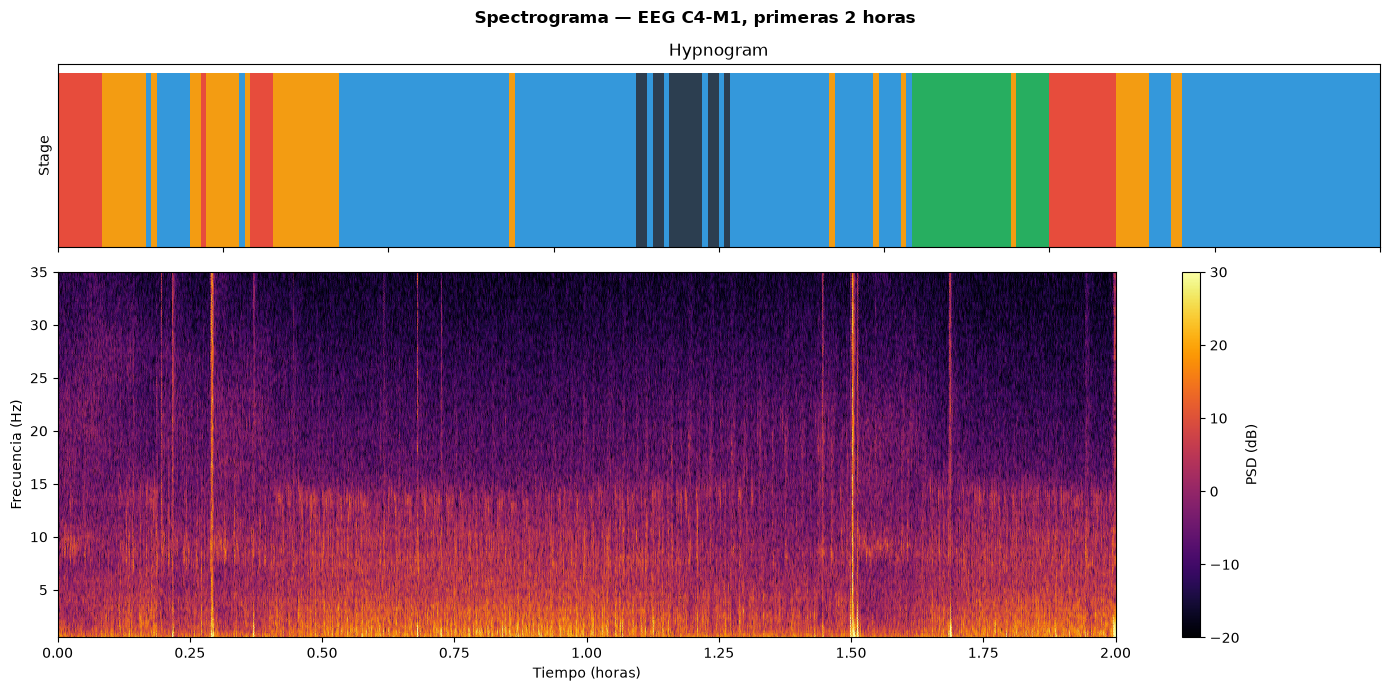

In [35]:
fig, (ax_hyp, ax_spec) = plt.subplots(
    2,
    1,
    figsize=(14, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 2]}
)

fig.suptitle(
    f"Spectrograma — {EEG_CHANNEL}, primeras {DURATION_H} horas",
    fontweight="bold"
)

# Hypnogram
colors = labels_2h["Annotation"].map(STAGE_COLORS).fillna("gray")

ax_hyp.bar(
    time_h,
    height=1,
    width=epoch_h,
    align="edge",
    color=colors
)

ax_hyp.set_yticks([])
ax_hyp.set_ylabel("Stage")
ax_hyp.set_title("Hypnogram")

# Spectrograma
t_h = t_spec / 3600

im = ax_spec.pcolormesh(
    t_h,
    f_plot,
    10 * np.log10(Sxx_plot + 1e-30),
    cmap="inferno",
    shading="gouraud",
    vmin=-20,
    vmax=30
)

fig.colorbar(im, ax=ax_spec, label="PSD (dB)")

ax_spec.set_ylabel("Frecuencia (Hz)")
ax_spec.set_xlabel("Tiempo (horas)")
ax_spec.set_xlim(0, DURATION_H)
ax_spec.set_ylim(0.5, 35)

plt.tight_layout()
plt.show()

raw_spec.close()

### Spectrograma EEG y evolución temporal de las etapas de sueño

En esta sección se analizaron las primeras 2 horas del canal `EEG C4-M1`. La señal se dividió en ventanas de 4 segundos con un solapamiento del 50%, y para cada ventana se calculó la potencia espectral. El resultado se representa mediante un spectrograma:

* eje X: tiempo en horas;
* eje Y: frecuencia en Hz;
* color: potencia de la señal en dB.

En la parte superior se muestra el hypnogram correspondiente al mismo intervalo, donde cada color representa una etapa de sueño distinta.

Como observación inicial, la mayor parte de la potencia se concentra en frecuencias bajas, especialmente por debajo de 10 Hz, lo cual es esperable en señales EEG de sueño. También se observan cambios en el contenido frecuencial a medida que varían las etapas del sueño y algunos eventos verticales de mayor intensidad, que podrían corresponder a transiciones, movimientos o posibles artefactos. Esta visualización permite relacionar la evolución temporal de las etapas con cambios en la actividad espectral del EEG.


---
## 13. Resumen — checklist antes de avanzar

Antes de pasar a preprocesamiento o modelado, verificar:

In [17]:
print("=" * 55)
print("  CHECKLIST PRE-MODELADO")
print("=" * 55)

checks = [
    ("Todos los sujetos tienen labels",        len(missing_labels) == 0),
    ("Canales consistentes entre sujetos",     unique_channel_sets == 1),
    ("Mismo sampling rate en todos",           df_info['sfreq'].nunique() == 1),
    ("No hay valores NaN",                     df_stats['% NaN'].max() == 0),
    ("Epochs malos < 20%",                     pct_bad < 20),
]

for label, ok in checks:
    icon = "✅" if ok else "❌"
    print(f"  {icon}  {label}")

print()
print("Próximos pasos recomendados:")
print("  1. Filtrado de señal (bandpass 0.5–35 Hz)")
print("  2. Rechazo de artefactos (ICA o umbral de amplitud)")
print("  3. Segmentación en epochs de 30s alineados con labels")
print("  4. Extracción de features espectrales por banda")
print("  5. Estrategia para clase desbalanceada (class weights / SMOTE)")
print("  6. Split sujeto-independiente (no mezclar sujetos entre train/test)")

  CHECKLIST PRE-MODELADO
  ✅  Todos los sujetos tienen labels
  ✅  Canales consistentes entre sujetos
  ✅  Mismo sampling rate en todos
  ✅  No hay valores NaN
  ✅  Epochs malos < 20%

Próximos pasos recomendados:
  1. Filtrado de señal (bandpass 0.5–35 Hz)
  2. Rechazo de artefactos (ICA o umbral de amplitud)
  3. Segmentación en epochs de 30s alineados con labels
  4. Extracción de features espectrales por banda
  5. Estrategia para clase desbalanceada (class weights / SMOTE)
  6. Split sujeto-independiente (no mezclar sujetos entre train/test)


## Introducción a MNE y a la estructura de los archivos EDF

### ¿Qué es MNE?

**MNE-Python** es una librería de Python de código abierto diseñada para explorar, visualizar y analizar señales neurofisiológicas y biomédicas, como EEG, MEG, EOG, ECG y EMG.

En este proyecto se utiliza principalmente para trabajar con archivos **EDF** (*European Data Format*), un formato frecuente para almacenar registros biomédicos.

Un archivo EDF puede contener:

* señales registradas a lo largo del tiempo;
* nombres de los canales;
* frecuencia de muestreo;
* unidades físicas;
* duración de la grabación;
* información temporal;
* anotaciones, según el tipo de archivo.

Por lo tanto, un EDF no guarda solamente valores numéricos: también incluye información descriptiva sobre la medición.

---

### El módulo `mne.io`

Dentro de MNE, el módulo:

```python
mne.io
```

agrupa las funciones utilizadas para leer y escribir señales provenientes de diferentes formatos.

Como los archivos del dataset tienen extensión `.edf`, se utiliza:

```python
raw = mne.io.read_raw_edf(sample_path, preload=False)
```

Esta función lee el archivo EDF y crea un objeto llamado `raw`.

El objeto `raw` representa una **grabación continua**: contiene información sobre las señales, sus canales y sus metadatos. Además, permite acceder a los valores numéricos de las señales cuando sea necesario.

---

### ¿Qué significa `preload=False`?

El parámetro:

```python
preload=False
```

indica que MNE no debe cargar inmediatamente todas las muestras de la señal en la memoria RAM. MNE lee primero la información necesaria del archivo y carga los datos numéricos solamente cuando se solicitan.

---

### El objeto `raw`

`raw` es un objeto de MNE que representa los *datos continuos de una grabación*.

Se puede relacionar con un `DataFrame` de pandas con tiene atributos y métodos.

* En este caso, el objeto `raw` tiene atributos como `ch_names`, `n_times`, `times`, `info` y métodos como `get_channel_types()`.

*Algunos Atributos importantes*:

| Atributo            | Descripción                                                   |
| ------------------- | ------------------------------------------------------------- |
| `raw.ch_names`      | Lista con los nombres de los canales                          |
| `raw.info`          | Estructura que contiene metadatos de la grabación             |
| `raw.info["sfreq"]` | Frecuencia de muestreo en Hz                                  |
| `raw.n_times`       | Cantidad total de muestras temporales                         |
| `raw.times`         | Array con el instante temporal correspondiente a cada muestra |
| `raw.duration`      | Duración total de la grabación en segundos                    |

---

#### Nombres de los canales: `raw.ch_names`

```python
raw.ch_names
```

devuelve una lista con los nombres de los canales presentes en el archivo.

Ejemplo:

```python
[
    "EEG F4-M1",
    "EEG C4-M1",
    "EEG O2-M1",
    "EEG C3-M2",
    "EMG chin",
    "EOG E1-M2",
    "EOG E2-M2",
    "ECG"
]
```

---

#### Metadatos: `raw.info`

```python
raw.info
```

contiene información descriptiva sobre la grabación. Se comporta de forma similar a un diccionario de Python.

Ejemplo:

```python
raw.info["sfreq"]
```

devuelve la frecuencia de muestreo.


---

#### Cantidad de muestras: `raw.n_times`

```python
raw.n_times
```

indica cuántas muestras temporales tiene la grabación completa.

Por ejemplo:

```python
raw.n_times
# 6_566_400
```

significa que cada canal contiene 6 566 400 valores.

La duración aproximada de la grabación puede calcularse como:

```python
duration_seconds = raw.n_times / raw.info["sfreq"]
```

---

#### Vector temporal: `raw.times`

```python
raw.times
```

es un array que indica el instante temporal asociado con cada muestra, expresado en segundos.

Para una frecuencia de muestreo de `256 Hz`, los primeros valores serán aproximadamente:

```python
[
    0.000000,
    0.003906,
    0.007812,
    0.011719,
    ...
]
```

La separación temporal entre dos muestras es:

```python
1 / 256  # 0.00390625 segundos
```

También puede obtenerse la duración directamente mediante:

```python
raw.duration
```

---

### Ejemplo: Mostrar información básica de una grabación


```python
print(f"Archivo:             {sample_file}")
print(f"Canales ({len(raw.ch_names)}):      {raw.ch_names}")
print(f"Frecuencia muestreo: {raw.info['sfreq']} Hz")
print(f"Duración:            {raw.duration / 3600:.2f} horas")
print(f"Total de muestras:   {raw.n_times:,}")
```

Permite entender:

* qué archivo se está analizando;
* cuántos canales contiene;
* cómo se llaman los canales;
* cuál es la frecuencia de muestreo;
* cuánto dura la grabación;
* cuántas muestras contiene.

---

### Atributos/Metadatos

Los valores:

```python
raw.ch_names
raw.info["sfreq"]
raw.n_times
raw.times
```

son **atributos** o **metadatos** de la grabación.

**NO** son *features* que se utilizarán para entrenar un modelo de machine learning.

---

### Tipos de canal

Cada canal tiene un tipo asociado:

| Tipo  | Significado                  |
| ----- | ---------------------------- |
| `eeg` | Actividad eléctrica cerebral |
| `eog` | Movimientos oculares         |
| `emg` | Actividad muscular           |
| `ecg` | Actividad cardíaca           |

MNE permite consultar los tipos registrados con:

```python
raw.get_channel_types()
```

---

#### Importante: consultar un tipo no significa detectarlo correctamente

El método:

```python
raw.get_channel_types()
```

no analiza la forma de la señal para descubrir si se trata de EEG, ECG, EOG o EMG.

Solamente devuelve los tipos que MNE tiene asignados en ese momento.

---

### Posibilidad: Asignación manual recomendada

Como los canales del dataset son conocidos, puede definirse un diccionario:

```python
channel_types = {
    "EEG F4-M1": "eeg",
    "EEG C4-M1": "eeg",
    "EEG O2-M1": "eeg",
    "EEG C3-M2": "eeg",
    "EMG chin":   "emg",
    "EOG E1-M2":  "eog",
    "EOG E2-M2":  "eog",
    "ECG":        "ecg",
}
```

Luego, los tipos correctos se pueden asignar mediante:

```python
raw.set_channel_types(channel_types)
```

Finalmente, pueden verificarse con:

```python
print("Tipos de canal:")
for ch, channel_type in zip(raw.ch_names, raw.get_channel_types()):
    print(f"  {ch:<20} → {channel_type}")
```

La salida esperada es:

```text
EEG F4-M1            → eeg
EEG C4-M1            → eeg
EEG O2-M1            → eeg
EEG C3-M2            → eeg
EMG chin             → emg
EOG E1-M2            → eog
EOG E2-M2            → eog
ECG                  → ecg
```

---

### Ayudas

Para consultar la ayuda:

```python
help(raw)
```

Para listar atributos y métodos disponibles:

```python
dir(raw)
```

Para inspeccionar los metadatos:

```python
print(raw.info)
```

Para observar las claves disponibles dentro de `info`:

```python
print(raw.info.keys())
```

---

### Resumen conceptual

```text
Archivo EDF
    ↓
mne.io.read_raw_edf(...)
    ↓
Objeto raw
    ├── señales biomédicas continuas
    ├── nombres de canales: raw.ch_names
    ├── frecuencia de muestreo: raw.info["sfreq"]
    ├── cantidad de muestras: raw.n_times
    ├── vector temporal: raw.times
    ├── duración: raw.duration
    └── métodos para procesar e inspeccionar la señal
```

La idea principal es que `raw` no es solamente una matriz de números. Es un objeto estructurado que reúne las señales, sus metadatos y distintos métodos para trabajar con ellas.


### Análisis espectral de señales EEG mediante PSD

## ¿Qué es la PSD?

La **Power Spectral Density** o **PSD** (*densidad espectral de potencia*) permite analizar cómo se distribuye la potencia de una señal entre distintas frecuencias.

Hasta este punto, las señales se visualizaron en el dominio temporal:

```text
amplitud vs. tiempo
```

Con la PSD, se estudian en el dominio frecuencial:

```text
potencia vs. frecuencia
```

Esto permite responder preguntas como:

* ¿En qué frecuencias se concentra principalmente la energía de la señal?
* ¿Predominan las componentes lentas o rápidas?
* ¿Existen diferencias entre los canales EEG?
* ¿Se observan bandas frecuenciales asociadas con etapas del sueño?


---

## Cálculo de PSD con el método de Welch

La PSD se calcula mediante:

```python
spectrum = raw_psd.compute_psd(
    method="welch",
    fmin=0.5,
    fmax=35,
    n_fft=1024,
    picks=eeg_channels
)
```

El método de Welch funciona conceptualmente de la siguiente forma:

```text
señal completa
    ↓
dividir en ventanas temporales
    ↓
calcular FFT de cada ventana
    ↓
obtener la potencia por frecuencia
    ↓
promediar los resultados
    ↓
PSD más estable
```

A diferencia de calcular una única FFT sobre toda la señal, Welch promedia varios espectros.

Esto permite obtener una curva más estable y menos sensible a ruido, movimientos o eventos aislados.

---

## Significado de los parámetros


### `n_fft=1024`

Indica cuántos puntos se utilizan para calcular cada FFT.

Como la frecuencia de muestreo es:

```text
256 Hz
```

la resolución frecuencial aproximada es:

```text
256 / 1024 = 0.25 Hz
```

Esto significa que el espectro se evalúa aproximadamente cada:

```text
0.25 Hz
```

---

### `picks=eeg_channels`

Indica qué canales deben utilizarse para calcular la PSD.

En este caso:

```python
eeg_channels = [
    "EEG F4-M1",
    "EEG C4-M1",
    "EEG O2-M1",
    "EEG C3-M2"
]
```

Por lo tanto, el espectro se calcula solamente para los cuatro canales EEG.

---

## ¿Qué contiene `spectrum`?

La variable:

```python
spectrum
```

contiene un objeto generado por MNE con:

* frecuencias analizadas;
* valores de PSD;
* canales utilizados;
* metadatos asociados;
* métodos para graficar el resultado.

El gráfico se genera con:

```python
spectrum.plot()
```

---



## Resumen conceptual

```text
grabación EEG
    ↓
seleccionar primeros 10 minutos
    ↓
quedarse solo con canales EEG
    ↓
calcular PSD con Welch
    ↓
analizar potencia por frecuencia
    ↓
interpretar bandas relevantes para sleep staging
```

La PSD permite pasar de una inspección visual de la señal en el tiempo a un análisis más útil para estudiar patrones frecuenciales relacionados con las etapas del sueño.
